# Normalized Laplacian energy of learned face embeddings

Measure how smoothly the learned face representations vary over each validation solid. Compare the final classifier-input embeddings from the learned message-passing ladder:

1. Geometry FaceCNN
2. Frozen FaceCNN + 2-hop Chebyshev GCN
3. Joint FaceCNN + 2-hop Chebyshev GCN
4. Joint FaceCNN + static-edge gated GCN
5. Joint FaceCNN + updated-edge gated GCN

The three Stage 1.5 alternatives are intentionally omitted here. Their classifier inputs concatenate heterogeneous handcrafted features (Laplacian coordinates, categorical WL histories or graphlet counts), whereas the five representations above are learned 64-dimensional face embeddings. This keeps the smoothness comparison interpretable.

Use the saved epoch-20 checkpoints and the full validation split. No training occurs.

In [1]:
from pathlib import Path
import os
import tempfile
import warnings

# Keep plotting caches writable in restricted notebook environments.
cache_root = Path(tempfile.gettempdir()) / "cs5284-embedding-analysis-cache"
(cache_root / "matplotlib").mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(cache_root / "matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(cache_root))
os.environ.setdefault("DGLBACKEND", "pytorch")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
warnings.filterwarnings("ignore", message="TypedStorage is deprecated.*", category=UserWarning)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm

from uvnet_project.load_mfcad import DATA_DIR, _load_sample, _load_splits
from uvnet_project.face_cnn import FaceCNN
from uvnet_project.classifier import Classifier
from uvnet_project.chebyshev import scaled_laplacian, collate_cheb, ChebFaceClassifier
from uvnet_project.anisotropic import collate_face_edges, AnisotropicFaceClassifier

project_dir = DATA_DIR.parent.parent
output_dir = project_dir / "results/embedding_analysis"
output_dir.mkdir(parents=True, exist_ok=True)
device = torch.device("cpu")
batch_size = 64  # solids; face and edge counts vary
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("Project:", project_dir)
print("Device:", device)


Project: /Users/yongjun/Workspace/NUS/CS5284/project
Device: cpu


## Load the exact saved models

Rebuild each architecture from its checkpoint configuration and load the epoch-20 state. The frozen GCN receives the completed Geometry FaceCNN embedding; the other graph models contain their own jointly trained FaceCNN.

In [2]:
model_specs = [
    ("Geometry", "baseline_run_01"),
    ("GCN frozen", "cheb2_frozen_run_01"),
    ("GCN joint", "cheb2_joint_run_01"),
    ("Edge static", "anisotropic_static_joint_run_01"),
    ("Edge updated", "anisotropic_updated_joint_run_01"),
]

def load_checkpoint(run):
    path = project_dir / "results" / run / "epoch_020/checkpoint.pt"
    if not path.is_file():
        raise FileNotFoundError(path)
    return torch.load(path, map_location="cpu", weights_only=True)


baseline_checkpoint = load_checkpoint("baseline_run_01")
baseline_config = baseline_checkpoint["config"]
embedding_dim = baseline_config["embedding_dim"]
hidden_dim = baseline_config["hidden_dim"]
num_classes = baseline_config["num_classes"]
in_channels = baseline_config["in_channels"]

geometry_model = nn.Sequential(
    FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels),
    Classifier(embedding_dim=embedding_dim, hidden_dim=hidden_dim,
               num_classes=num_classes),
)
geometry_model.load_state_dict(baseline_checkpoint["model_state_dict"], strict=True)


def load_cheb(run, joint):
    checkpoint = load_checkpoint(run)
    config = checkpoint["config"]
    face_cnn = (FaceCNN(config["embedding_dim"], config.get("in_channels", in_channels))
                if joint else None)
    model = ChebFaceClassifier(
        config["embedding_dim"], config["graph_dim"], config["hidden_dim"],
        config["cheb_hops"], config["num_classes"], face_cnn=face_cnn,
    )
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    return model


def load_edge(run):
    checkpoint = load_checkpoint(run)
    config = checkpoint["config"]
    face_cnn = FaceCNN(config["embedding_dim"], config.get("in_channels", in_channels))
    model = AnisotropicFaceClassifier(
        config["embedding_dim"], config["graph_dim"], config["hidden_dim"],
        config["edge_mode"], config["num_classes"],
        edge_in_channels=config.get("edge_in_channels", 6), face_cnn=face_cnn,
    )
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    return model


models = {
    "Geometry": geometry_model,
    "GCN frozen": load_cheb("cheb2_frozen_run_01", joint=False),
    "GCN joint": load_cheb("cheb2_joint_run_01", joint=True),
    "Edge static": load_edge("anisotropic_static_joint_run_01"),
    "Edge updated": load_edge("anisotropic_updated_joint_run_01"),
}
for model in models.values():
    model.to(device).eval()

model_table = pd.DataFrame([
    dict(model=name, run=run, embedding_dim=embedding_dim, epoch=20)
    for name, run in model_specs
]).set_index("model")
display(model_table)


,run,embedding_dim,epoch
model,,,
Geometry,baseline_run_01,64,20
GCN frozen,cheb2_frozen_run_01,64,20
GCN joint,cheb2_joint_run_01,64,20
Edge static,anisotropic_static_joint_run_01,64,20
Edge updated,anisotropic_updated_joint_run_01,64,20


## Extract classifier-input embeddings

Load validation solids in the supplied split order. For every batch, reproduce the five final embeddings immediately before their classification heads. Verify the resulting class predictions against the saved validation predictions before using the embeddings.

The Chebyshev models retain their training-time simple-graph Laplacian for inference. The smoothness metric below is evaluated separately on the original B-rep multigraph, preserving parallel edge multiplicity from distinct intersections.

In [3]:
validation_ids = _load_splits()["validation"]


class ValidationGraphDataset(Dataset):
    def __init__(self, sample_ids):
        self.sample_ids = list(sample_ids)

    def __len__(self):
        return len(self.sample_ids)

    def __getitem__(self, index):
        sample_id = self.sample_ids[index]
        solid = _load_sample(sample_id)
        graph = solid["graph"]
        grids = graph.ndata["x"].permute(0, 3, 1, 2).contiguous().float()
        edge_grids = graph.edata["x"].permute(0, 2, 1).contiguous().float()
        edge_index = torch.stack(graph.edges()).long()
        labels = torch.tensor(
            [face["segment"]["index"] for face in solid["faces"]], dtype=torch.long
        )
        return dict(sample_id=sample_id, graph=graph, grids=grids,
                    edge_grids=edge_grids, edge_index=edge_index, labels=labels)


validation_loader = DataLoader(
    ValidationGraphDataset(validation_ids), batch_size=batch_size, shuffle=False,
    num_workers=0, collate_fn=lambda samples: samples,
)


def cheb_embedding(model, geometry, laplacian):
    return torch.relu(model.conv(geometry, laplacian))


def edge_embedding(model, inputs):
    geometry = model.face_cnn(inputs.geometry)
    h = model.face_projection(geometry)
    e = (h.new_empty((0, h.shape[1])) if inputs.edge_grids.shape[0] == 0
         else model.edge_cnn(inputs.edge_grids))
    for layer in model.layers:
        h, e = layer(h, e, inputs)
    return h


def normalized_laplacian_energy(embedding, edge_index):
    # Return tr(H^T L_sym H) / ||H||_F^2 on a symmetric directed multigraph.
    h = embedding.double()
    src, dst = edge_index.long()
    n = h.shape[0]
    # The raw DGL graph stores both directions and preserves parallel B-rep edges.
    forward = torch.sort(src * n + dst).values
    reverse = torch.sort(dst * n + src).values
    if not torch.equal(forward, reverse):
        raise ValueError("Expected symmetric directed adjacency with matched multiplicity.")
    degree = torch.bincount(src, minlength=n).double()
    scaled = h / degree.clamp_min(1).sqrt().unsqueeze(1)
    numerator = 0.5 * (scaled[src] - scaled[dst]).square().sum()
    denominator = h.square().sum()
    if denominator <= 0:
        raise ValueError("Embedding has zero Frobenius norm.")
    return float(numerator / denominator), float(numerator), float(denominator)


cached_predictions = {
    name: torch.load(
        project_dir / "results" / run / "epoch_020/validation_predictions.pt",
        map_location="cpu", weights_only=True,
    )
    for name, run in model_specs
}

energy_rows = []
match_rows = []
row_start = 0
with torch.no_grad():
    for samples in tqdm(validation_loader, desc="Validation embedding energy"):
        counts = [len(sample["labels"]) for sample in samples]
        grids = torch.cat([sample["grids"] for sample in samples]).to(device)
        labels = torch.cat([sample["labels"] for sample in samples])

        cheb_batch, _ = collate_cheb([
            (sample["grids"], scaled_laplacian(sample["graph"]), sample["labels"])
            for sample in samples
        ])
        cheb_batch = cheb_batch.to(device)
        edge_batch, _ = collate_face_edges([
            (sample["grids"], sample["edge_grids"], sample["edge_index"], sample["labels"])
            for sample in samples
        ])
        edge_batch = edge_batch.to(device)

        geometry = models["Geometry"][0](grids)
        embeddings = {
            "Geometry": geometry,
            "GCN frozen": cheb_embedding(models["GCN frozen"], geometry,
                                           cheb_batch.laplacian),
        }
        joint_geometry = models["GCN joint"].face_cnn(grids)
        embeddings["GCN joint"] = cheb_embedding(
            models["GCN joint"], joint_geometry, cheb_batch.laplacian
        )
        embeddings["Edge static"] = edge_embedding(models["Edge static"], edge_batch)
        embeddings["Edge updated"] = edge_embedding(models["Edge updated"], edge_batch)

        logits = {
            "Geometry": models["Geometry"][1](embeddings["Geometry"]),
            "GCN frozen": models["GCN frozen"].classifier(embeddings["GCN frozen"]),
            "GCN joint": models["GCN joint"].classifier(embeddings["GCN joint"]),
            "Edge static": models["Edge static"].classifier(embeddings["Edge static"]),
            "Edge updated": models["Edge updated"].classifier(embeddings["Edge updated"]),
        }

        row_stop = row_start + len(labels)
        for name in models:
            cached = cached_predictions[name]
            if not torch.equal(labels, cached["labels"][row_start:row_stop]):
                raise ValueError(f"Validation label order mismatch: {name}")
            predicted = logits[name].argmax(1).cpu()
            expected = cached["predictions"][row_start:row_stop]
            match_rows.append(dict(model=name, matched=int((predicted == expected).sum()),
                                   faces=len(labels)))

            for sample, h in zip(samples, embeddings[name].cpu().split(counts)):
                energy, numerator, denominator = normalized_laplacian_energy(
                    h, sample["edge_index"]
                )
                energy_rows.append(dict(
                    sample_id=sample["sample_id"], model=name,
                    normalized_laplacian_energy=energy,
                    numerator=numerator, denominator=denominator,
                    faces=len(sample["labels"]), directed_edges=sample["edge_index"].shape[1],
                ))
        row_start = row_stop

if row_start != len(cached_predictions["Geometry"]["labels"]):
    raise ValueError("Did not process the full validation prediction table.")

energy_by_solid = pd.DataFrame(energy_rows)
prediction_reproduction = (pd.DataFrame(match_rows).groupby("model", sort=False).sum()
                           .reindex([name for name, _ in model_specs]))
prediction_reproduction["match_percent"] = (
    100 * prediction_reproduction["matched"] / prediction_reproduction["faces"]
)
display(prediction_reproduction.style.format({
    "matched": "{:,.0f}", "faces": "{:,.0f}", "match_percent": "{:.3f}%"
}))
minimum_match = prediction_reproduction["match_percent"].min()
if minimum_match < 99.9:
    raise ValueError(f"Prediction reproduction below 99.9%: {minimum_match:.3f}%")
if minimum_match < 100:
    print("Minor prediction differences are retained as a CPU-versus-original-evaluation diagnostic.")

energy_by_solid.to_csv(output_dir / "normalized_laplacian_energy_by_solid.csv", index=False)
prediction_reproduction.to_csv(output_dir / "embedding_prediction_reproduction.csv")
print(f"Measured {len(energy_by_solid):,} model-solid pairs across "
      f"{len(validation_ids):,} validation solids.")


Validation embedding energy:   0%|          | 0/49 [00:00<?, ?it/s]

,matched,faces,match_percent
model,,,
Geometry,"70,231","70,255",99.966%
GCN frozen,"70,255","70,255",100.000%
GCN joint,"70,255","70,255",100.000%
Edge static,"70,255","70,255",100.000%
Edge updated,"70,255","70,255",100.000%


Minor prediction differences are retained as a CPU-versus-original-evaluation diagnostic.
Measured 15,450 model-solid pairs across 3,090 validation solids.


## Normalized Laplacian energy

For a solid with face embedding matrix (H\in\mathbb{R}^{n\times d}) and symmetric normalized multigraph Laplacian (L_{\mathrm{sym}}), compute

\[
\mathcal{E}_{\mathrm{norm}}(H)
=\frac{\operatorname{tr}(H^\top L_{\mathrm{sym}}H)}{\lVert H\rVert_F^2}
=\frac{\tfrac12\sum_{(i,j)}
\left\lVert\frac{h_i}{\sqrt{d_i}}-\frac{h_j}{\sqrt{d_j}}\right\rVert_2^2}
{\sum_i\lVert h_i\rVert_2^2}.
\]

The ratio removes global embedding scale and is comparable across models. Lower values mean adjacent faces have more similar learned representations. Low energy is descriptive rather than automatically better: an extremely small value can indicate oversmoothing and loss of class boundaries.

All faces, including stock, remain in each solid because removing nodes would change the graph Laplacian. Aggregate by giving every validation solid equal weight. Error bars show the 95% confidence interval of the mean across solids.

,count,mean,std,median,min,max,sem,ci95
model,,,,,,,,
Geometry,"3,090",0.60551,0.04844,0.61140,0.37364,0.73484,0.000871,0.001708
GCN frozen,"3,090",0.20643,0.03057,0.20899,0.09705,0.28222,0.000550,0.001078
GCN joint,"3,090",0.21170,0.03176,0.21432,0.09852,0.30720,0.000571,0.001120
Edge static,"3,090",0.38421,0.06578,0.38404,0.18744,0.55110,0.001183,0.002319
Edge updated,"3,090",0.40482,0.06259,0.40274,0.21979,0.59775,0.001126,0.002207


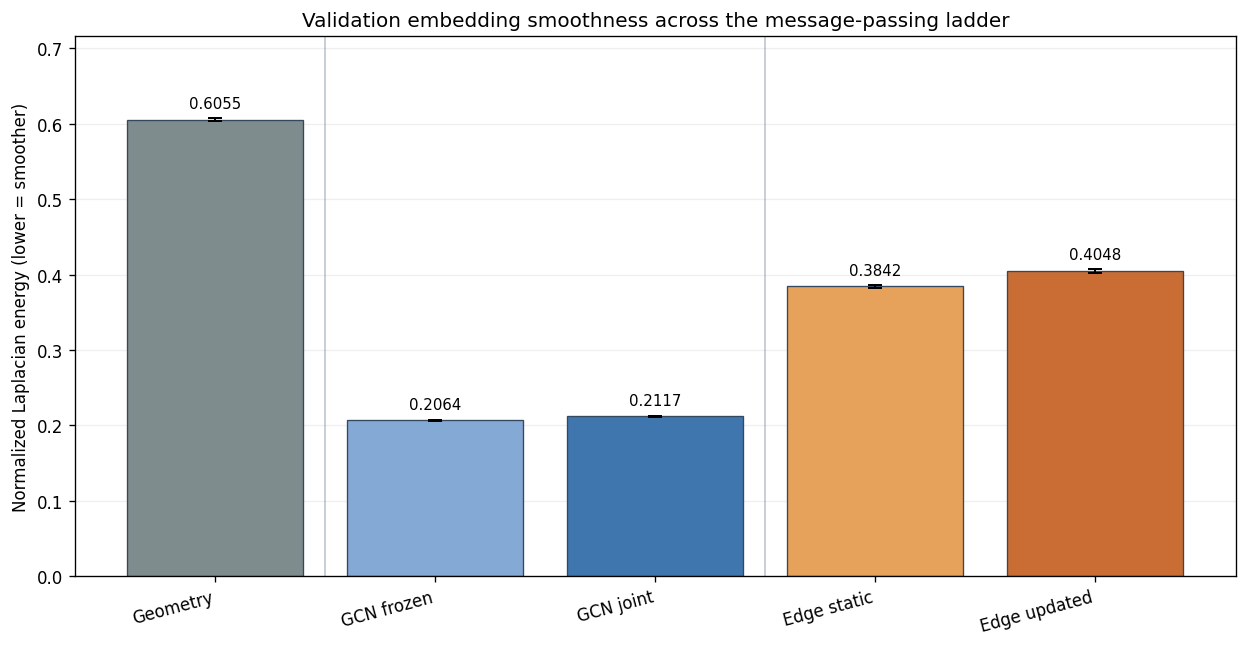

Saved: /Users/yongjun/Workspace/NUS/CS5284/project/results/embedding_analysis/normalized_laplacian_energy_bar.png


In [4]:
model_order = [name for name, _ in model_specs]
energy_summary = (
    energy_by_solid.groupby("model", sort=False)["normalized_laplacian_energy"]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .reindex(model_order)
)
energy_summary["sem"] = energy_summary["std"] / energy_summary["count"].pow(0.5)
energy_summary["ci95"] = 1.96 * energy_summary["sem"]
display(energy_summary.style.format({
    "count": "{:,.0f}", "mean": "{:.5f}", "std": "{:.5f}",
    "median": "{:.5f}", "min": "{:.5f}", "max": "{:.5f}",
    "sem": "{:.6f}", "ci95": "{:.6f}",
}))
energy_summary.to_csv(output_dir / "normalized_laplacian_energy_summary.csv")

colors = ["#7f8c8d", "#84a9d4", "#3f76ad", "#e6a15a", "#c96d35"]
fig, ax = plt.subplots(figsize=(10.5, 5.5))
x = range(len(model_order))
bars = ax.bar(
    x, energy_summary["mean"], yerr=energy_summary["ci95"],
    color=colors, edgecolor="#34495e", linewidth=0.8,
    capsize=4, error_kw={"elinewidth": 1.2, "capthick": 1.2},
)
for bar, value in zip(bars, energy_summary["mean"]):
    ax.annotate(f"{value:.4f}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 7), textcoords="offset points", ha="center", fontsize=9)
ax.axvline(0.5, color="#718096", linewidth=1, alpha=0.45)
ax.axvline(2.5, color="#718096", linewidth=1, alpha=0.45)
ax.set_xticks(list(x), model_order, rotation=15, ha="right")
ax.set_ylabel("Normalized Laplacian energy (lower = smoother)")
ax.set_title("Validation embedding smoothness across the message-passing ladder")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.set_ylim(0, max((energy_summary["mean"] + energy_summary["ci95"]).max() * 1.18, 0.01))
fig.tight_layout()
figure_path = output_dir / "normalized_laplacian_energy_bar.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)


## Interpretation

The learned graph representations are substantially smoother than the Geometry embedding, but the two graph operators behave differently.

- **Geometry:** mean normalized energy **0.6055**.
- **GCN frozen:** **0.2064**, a **65.9% reduction** from Geometry. The controlled frozen comparison shows that the Chebyshev graph layer itself produces strong neighbour smoothing.
- **GCN joint:** **0.2117**, only **2.6% above** GCN frozen. Jointly updating the FaceCNN changes predictive performance more than it changes the overall smoothness level.
- **Edge static:** **0.3842**, a **36.5% reduction** from Geometry.
- **Edge updated:** **0.4048**, a **33.1% reduction** from Geometry and **5.4% above** Edge static.

The isotropic GCN therefore smooths most aggressively. The edge-conditioned models still make adjacent faces more similar than Geometry alone, while preserving considerably more local variation than the GCN. Edge updating preserves slightly more variation than static encoded edges. Read together with the accuracy and confusion results, this supports a useful mechanism-level interpretation: the best Edge model does not win by making every neighbour uniformly similar; its learned edge gates allow more selective propagation across different face relationships.

This metric alone does not measure class separation, and lower energy is not automatically better. The narrow confidence intervals reflect the large validation sample of 3,090 solids rather than a claim that the modelling choices are causally isolated. A CPU replay reproduces all cached graph-model predictions exactly and 70,231 of 70,255 Geometry predictions (99.966%); the 24 Geometry differences are numerical boundary cases from the original evaluation environment.


## Shallow-topology contribution after the trained first layer

For a fairer dimensional comparison, isolate the topology contribution made by each Stage 1.5 model to its first 128-dimensional hidden pre-activation:

\[
z_{\mathrm{topo}} = W_{\mathrm{topo}}h_{\mathrm{topo}}.
\]

- **Laplacian:** project the eight positional coordinates through the topology columns of the trained classifier's `linear1` weight.
- **WL (T=3):** sum the trained colour embeddings, which is the implementation-equivalent categorical topology projection.
- **Graphlets (≤4):** project the 15 standardized orbit features through the topology columns of `linear1`.

All three outputs therefore have dimension 128. Geometry, classifier bias and ReLU are excluded because they cannot be assigned solely to topology. Feature construction still follows each trained pipeline: Laplacian coordinates preserve multiedge multiplicity, while WL and graphlets use the simple undirected graph. The energy is evaluated on the same raw B-rep multigraph for all three.

The Laplacian model uses eight coordinates because the model notebook adopted the editable eight-vector default used by the course's Graph Transformer LapPE example. It was a course-aligned compact spectral bandwidth, not a dimension selected through validation tuning.


In [5]:
from uvnet_project.laplacian import laplacian_positional_encoding
from uvnet_project.wl import wl_node_colors, wl_color_maps, encode_wl_colors
from uvnet_project.geometry_wl import WLClassifier
from uvnet_project.graphlets import graphlet_degree_vectors

laplacian_checkpoint = load_checkpoint("laplacian_run_01")
wl_checkpoint = load_checkpoint("wl3_frozen_run_01")
graphlet_checkpoint = load_checkpoint("graphlet4_frozen_run_01")

laplacian_dim = laplacian_checkpoint["config"]["pos_enc_dim"]
laplacian_topology_weight = laplacian_checkpoint["model_state_dict"]["linear1.weight"][
    :, -laplacian_dim:
]

wl_vocabulary = wl_checkpoint["extra"]["wl_vocabulary"]
wl_maps = wl_color_maps(wl_vocabulary)
wl_model = WLClassifier(
    embedding_dim=wl_checkpoint["config"]["embedding_dim"],
    hidden_dim=wl_checkpoint["config"]["hidden_dim"],
    vocabulary=wl_vocabulary,
    num_classes=wl_checkpoint["config"]["num_classes"],
)
wl_model.load_state_dict(wl_checkpoint["model_state_dict"], strict=True)
wl_model.eval()

graphlet_max_nodes = graphlet_checkpoint["config"]["max_graphlet_nodes"]
graphlet_dim = graphlet_checkpoint["config"]["graphlet_dim"]
graphlet_mean = graphlet_checkpoint["extra"]["graphlet_mean"].float()
graphlet_scale = graphlet_checkpoint["extra"]["graphlet_scale"].float()
graphlet_topology_weight = graphlet_checkpoint["model_state_dict"]["linear1.weight"][
    :, -graphlet_dim:
]

hidden_widths = {
    "Laplacian (k=8)": laplacian_topology_weight.shape[0],
    "WL (T=3)": wl_model.color_projection.embedding_dim,
    "Graphlets (≤4)": graphlet_topology_weight.shape[0],
}
if set(hidden_widths.values()) != {128}:
    raise ValueError(f"Expected a common 128-dimensional hidden width: {hidden_widths}")

shallow_specs = [
    ("Laplacian (k=8)", laplacian_dim, 128, "trained linear1 topology block"),
    ("WL (T=3)", wl_vocabulary["iterations"] + 1, 128, "trained colour projection"),
    ("Graphlets (≤4)", graphlet_dim, 128, "trained linear1 topology block"),
]
display(pd.DataFrame(
    shallow_specs,
    columns=["feature", "native topology inputs", "compared dimension", "projection"],
).set_index("feature"))


,native topology inputs,compared dimension,projection
feature,,,
Laplacian (k=8),8,128,trained linear1 topology block
WL (T=3),4,128,trained colour projection
Graphlets (≤4),15,128,trained linear1 topology block


In [6]:
shallow_rows = []
shallow_dataset = ValidationGraphDataset(validation_ids)

with torch.no_grad():
    for sample in tqdm(shallow_dataset, desc="Projected shallow-topology energy"):
        graph = sample["graph"]

        laplacian_raw = laplacian_positional_encoding(graph, laplacian_dim)
        laplacian_topology = laplacian_raw @ laplacian_topology_weight.T

        wl_tokens = encode_wl_colors(
            wl_node_colors(graph, wl_vocabulary["iterations"]),
            wl_vocabulary,
            wl_maps,
        )
        wl_values = wl_model.color_projection(wl_tokens)
        wl_known = (wl_tokens != wl_model.unknown_indices).unsqueeze(-1)
        wl_topology = (wl_values * wl_known).sum(dim=1)

        graphlet_raw = graphlet_degree_vectors(
            graph, max_nodes=graphlet_max_nodes, normalize=True
        )
        graphlet_standardized = (graphlet_raw - graphlet_mean) / graphlet_scale
        graphlet_topology = graphlet_standardized @ graphlet_topology_weight.T

        topology_contributions = {
            "Laplacian (k=8)": laplacian_topology,
            "WL (T=3)": wl_topology,
            "Graphlets (≤4)": graphlet_topology,
        }
        for feature, topology in topology_contributions.items():
            energy, numerator, denominator = normalized_laplacian_energy(
                topology, sample["edge_index"]
            )
            shallow_rows.append(dict(
                sample_id=sample["sample_id"], feature=feature,
                normalized_laplacian_energy=energy,
                numerator=numerator, denominator=denominator,
                dimension=topology.shape[1], faces=len(sample["labels"]),
                directed_edges=sample["edge_index"].shape[1],
            ))

shallow_energy_by_solid = pd.DataFrame(shallow_rows)
if set(shallow_energy_by_solid["dimension"]) != {128}:
    raise ValueError("Shallow topology contributions do not share dimension 128.")
shallow_energy_by_solid.to_csv(
    output_dir / "shallow_topology_laplacian_energy_by_solid.csv", index=False
)
print(f"Measured {len(shallow_energy_by_solid):,} feature-solid pairs across "
      f"{len(validation_ids):,} validation solids.")


Projected shallow-topology energy:   0%|          | 0/3090 [00:00<?, ?it/s]

Measured 9,270 feature-solid pairs across 3,090 validation solids.


,count,mean,std,median,min,max,sem,ci95
feature,,,,,,,,
Laplacian (k=8),"3,090",0.81660,0.11650,0.80682,0.48445,1.30800,0.002096,0.004108
WL (T=3),"3,090",0.40519,0.07622,0.39064,0.23629,0.64222,0.001371,0.002687
Graphlets (≤4),"3,090",0.80404,0.22680,0.83487,0.13734,1.23684,0.004080,0.007997


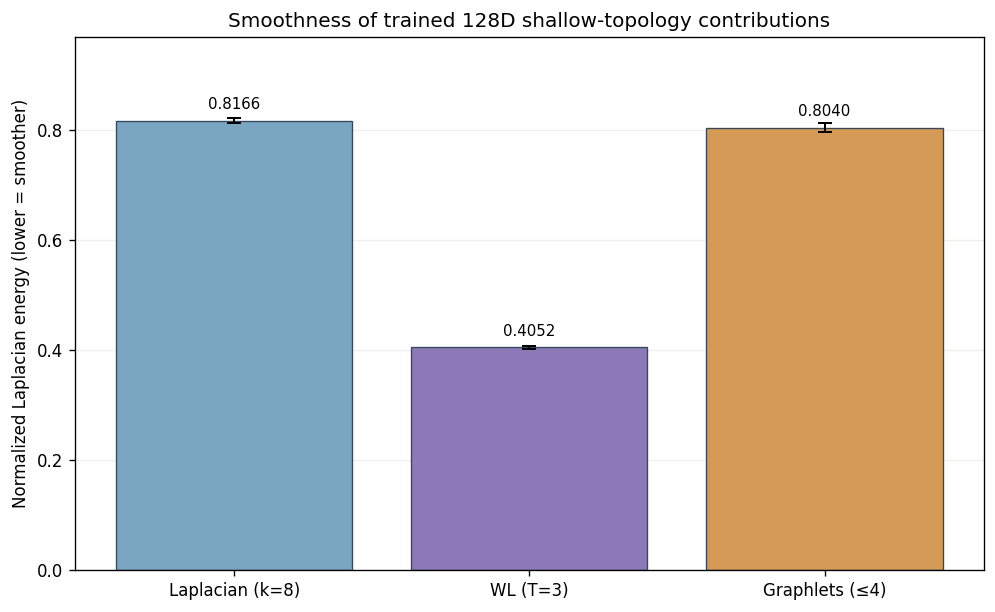

Saved: /Users/yongjun/Workspace/NUS/CS5284/project/results/embedding_analysis/shallow_topology_laplacian_energy_bar.png


In [7]:
shallow_order = [name for name, *_ in shallow_specs]
shallow_summary = (
    shallow_energy_by_solid.groupby("feature", sort=False)["normalized_laplacian_energy"]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .reindex(shallow_order)
)
shallow_summary["sem"] = shallow_summary["std"] / shallow_summary["count"].pow(0.5)
shallow_summary["ci95"] = 1.96 * shallow_summary["sem"]
display(shallow_summary.style.format({
    "count": "{:,.0f}", "mean": "{:.5f}", "std": "{:.5f}",
    "median": "{:.5f}", "min": "{:.5f}", "max": "{:.5f}",
    "sem": "{:.6f}", "ci95": "{:.6f}",
}))
shallow_summary.to_csv(output_dir / "shallow_topology_laplacian_energy_summary.csv")

fig, ax = plt.subplots(figsize=(8.4, 5.2))
x = range(len(shallow_order))
bars = ax.bar(
    x, shallow_summary["mean"], yerr=shallow_summary["ci95"],
    color=["#7aa6c2", "#8b79b8", "#d59a55"], edgecolor="#34495e",
    linewidth=0.8, capsize=4,
    error_kw={"elinewidth": 1.2, "capthick": 1.2},
)
for bar, value in zip(bars, shallow_summary["mean"]):
    ax.annotate(f"{value:.4f}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 7), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(list(x), shallow_order)
ax.set_ylabel("Normalized Laplacian energy (lower = smoother)")
ax.set_title("Smoothness of trained 128D shallow-topology contributions")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.set_ylim(0, max((shallow_summary["mean"] + shallow_summary["ci95"]).max() * 1.18, 0.01))
fig.tight_layout()
shallow_figure_path = output_dir / "shallow_topology_laplacian_energy_bar.png"
fig.savefig(shallow_figure_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", shallow_figure_path)


### Shallow-topology interpretation

- **WL (T=3): 0.4052** — still substantially smoother than the other shallow topology contributions.
- **Graphlets (≤4): 0.8040**.
- **Laplacian (k=8): 0.8166**.

Matching all three at 128 dimensions does not remove the separation. It instead brings the projected Laplacian and graphlet contributions close together, while WL remains about half their energy. The earlier ordering was therefore not simply caused by comparing 8, 128 and 15 dimensions.

The trained projection can change each signal's energy, so this result describes what each shallow classifier actually passes from topology into its hidden pre-activation. WL colour histories provide a relatively smooth local signal. Graphlet contributions remain sensitive to exact local motifs, while the retained nontrivial Laplacian modes are explicitly non-constant spectral coordinates. This is still not a model-quality ranking: low energy can also mean that a representation varies less across boundaries where class-discriminating changes occur.


## Error-enriched t-SNE visualization of learned face embeddings

Visualize the 64-dimensional classifier-input embeddings for **Geometry**, **GCN joint**, and **Edge updated**, coloured by ground-truth face class.

Use one fixed error-enriched validation sample for all three panels. First include the union of every face misclassified by any of the three models. Let \(M\) be the largest union-error count among the ground-truth classes. For every class, add faces correctly classified by all three models until the class has up to \(2M\) faces. This gives even the hardest class at least as many unambiguous correct references as errors. Classes with fewer than \(2M\) validation faces contribute their full available population; points are never duplicated. Stock is included under the same rule.

Reduce each model independently to 50 PCA components and then run t-SNE with identical settings and seed. The same face indices appear in every panel.

t-SNE preserves local neighbourhoods rather than global distances. Its axes, orientation, absolute cluster spacing and layouts are arbitrary, so compare local class mixing and separation rather than matching coordinates between panels.


In [8]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import numpy as np

tsne_models = ["Geometry", "GCN joint", "Edge updated"]
labels_all = cached_predictions["Geometry"]["labels"].cpu()
if any(not torch.equal(labels_all, cached_predictions[name]["labels"].cpu())
       for name in tsne_models):
    raise ValueError("Cached validation labels differ across t-SNE models.")

# Recover supplied class names without imposing a hand-written label order.
class_names = {}
for sample_id in validation_ids:
    for face in _load_sample(sample_id)["faces"]:
        segment = face["segment"]
        class_names.setdefault(int(segment["index"]), segment["name"])
    if len(class_names) == num_classes:
        break
if sorted(class_names) != list(range(num_classes)):
    raise ValueError(f"Incomplete class-name map: {class_names}")

wrong_masks = {
    name: cached_predictions[name]["predictions"].cpu() != labels_all
    for name in tsne_models
}
any_wrong = torch.stack(list(wrong_masks.values())).any(dim=0)
all_correct = ~any_wrong
union_error_counts = torch.bincount(labels_all[any_wrong], minlength=num_classes)
max_class_errors = int(union_error_counts.max())
target_per_class = 2 * max_class_errors

sample_generator = torch.Generator().manual_seed(0)
selected_parts = []
selection_rows = []
for class_index in range(num_classes):
    class_errors = torch.where((labels_all == class_index) & any_wrong)[0]
    class_correct = torch.where((labels_all == class_index) & all_correct)[0]
    correct_target = min(
        len(class_correct),
        max(len(class_errors), target_per_class - len(class_errors)),
    )
    sampled_correct = class_correct[
        torch.randperm(len(class_correct), generator=sample_generator)[:correct_target]
    ]
    selected_parts.extend([class_errors, sampled_correct])
    selection_rows.append(dict(
        class_index=class_index, class_name=class_names[class_index],
        validation_faces=int((labels_all == class_index).sum()),
        union_errors=len(class_errors), sampled_all_model_correct=len(sampled_correct),
        sampled_total=len(class_errors) + len(sampled_correct),
    ))

selected_indices = torch.cat(selected_parts).sort().values
selected_mask = torch.zeros(len(labels_all), dtype=torch.bool)
selected_mask[selected_indices] = True
selected_labels = labels_all[selected_indices]
selection_table = pd.DataFrame(selection_rows).set_index("class_name")
display(selection_table)
print(f"Largest class-level union-error pool: M={max_class_errors:,}")
print(f"Target per sufficiently large class: 2M={target_per_class:,}")
print(f"Selected {len(selected_indices):,} aligned faces, including all "
      f"{int(any_wrong.sum()):,} union-error faces.")


,class_index,validation_faces,union_errors,sampled_all_model_correct,sampled_total
class_name,,,,,
rectangular_through_slot,0,924,7,917,924
triangular_through_slot,1,2985,1298,1298,2596
rectangular_passage,2,4390,813,1783,2596
triangular_passage,3,6804,786,1810,2596
6sides_passage,4,1892,1,1891,1892
rectangular_through_step,5,2883,608,1988,2596
2sides_through_step,6,1804,259,1545,1804
slanted_through_step,7,2730,3,2593,2596
rectangular_blind_step,8,1660,52,1608,1660


Largest class-level union-error pool: M=1,298
Target per sufficiently large class: 2M=2,596
Selected 36,714 aligned faces, including all 7,533 union-error faces.


In [9]:
selected_embeddings = {name: [] for name in tsne_models}
global_start = 0

with torch.no_grad():
    for samples in tqdm(validation_loader, desc="Extract aligned t-SNE embeddings"):
        counts = [len(sample["labels"]) for sample in samples]
        grids = torch.cat([sample["grids"] for sample in samples]).to(device)

        cheb_batch, _ = collate_cheb([
            (sample["grids"], scaled_laplacian(sample["graph"]), sample["labels"])
            for sample in samples
        ])
        cheb_batch = cheb_batch.to(device)
        edge_batch, _ = collate_face_edges([
            (sample["grids"], sample["edge_grids"], sample["edge_index"], sample["labels"])
            for sample in samples
        ])
        edge_batch = edge_batch.to(device)

        geometry = models["Geometry"][0](grids)
        joint_geometry = models["GCN joint"].face_cnn(grids)
        batch_embeddings = {
            "Geometry": geometry,
            "GCN joint": cheb_embedding(
                models["GCN joint"], joint_geometry, cheb_batch.laplacian
            ),
            "Edge updated": edge_embedding(models["Edge updated"], edge_batch),
        }

        global_stop = global_start + len(grids)
        batch_selection = selected_mask[global_start:global_stop]
        for name in tsne_models:
            selected_embeddings[name].append(batch_embeddings[name][batch_selection].cpu())
        global_start = global_stop

if global_start != len(labels_all):
    raise ValueError("Embedding extraction did not cover all validation faces.")
selected_embeddings = {name: torch.cat(parts).numpy()
                       for name, parts in selected_embeddings.items()}
if any(len(values) != len(selected_indices) for values in selected_embeddings.values()):
    raise ValueError("Aligned t-SNE sample length mismatch.")
print({name: values.shape for name, values in selected_embeddings.items()})


Extract aligned t-SNE embeddings:   0%|          | 0/49 [00:00<?, ?it/s]

{'Geometry': (36714, 64), 'GCN joint': (36714, 64), 'Edge updated': (36714, 64)}


Reused aligned t-SNE coordinate cache.


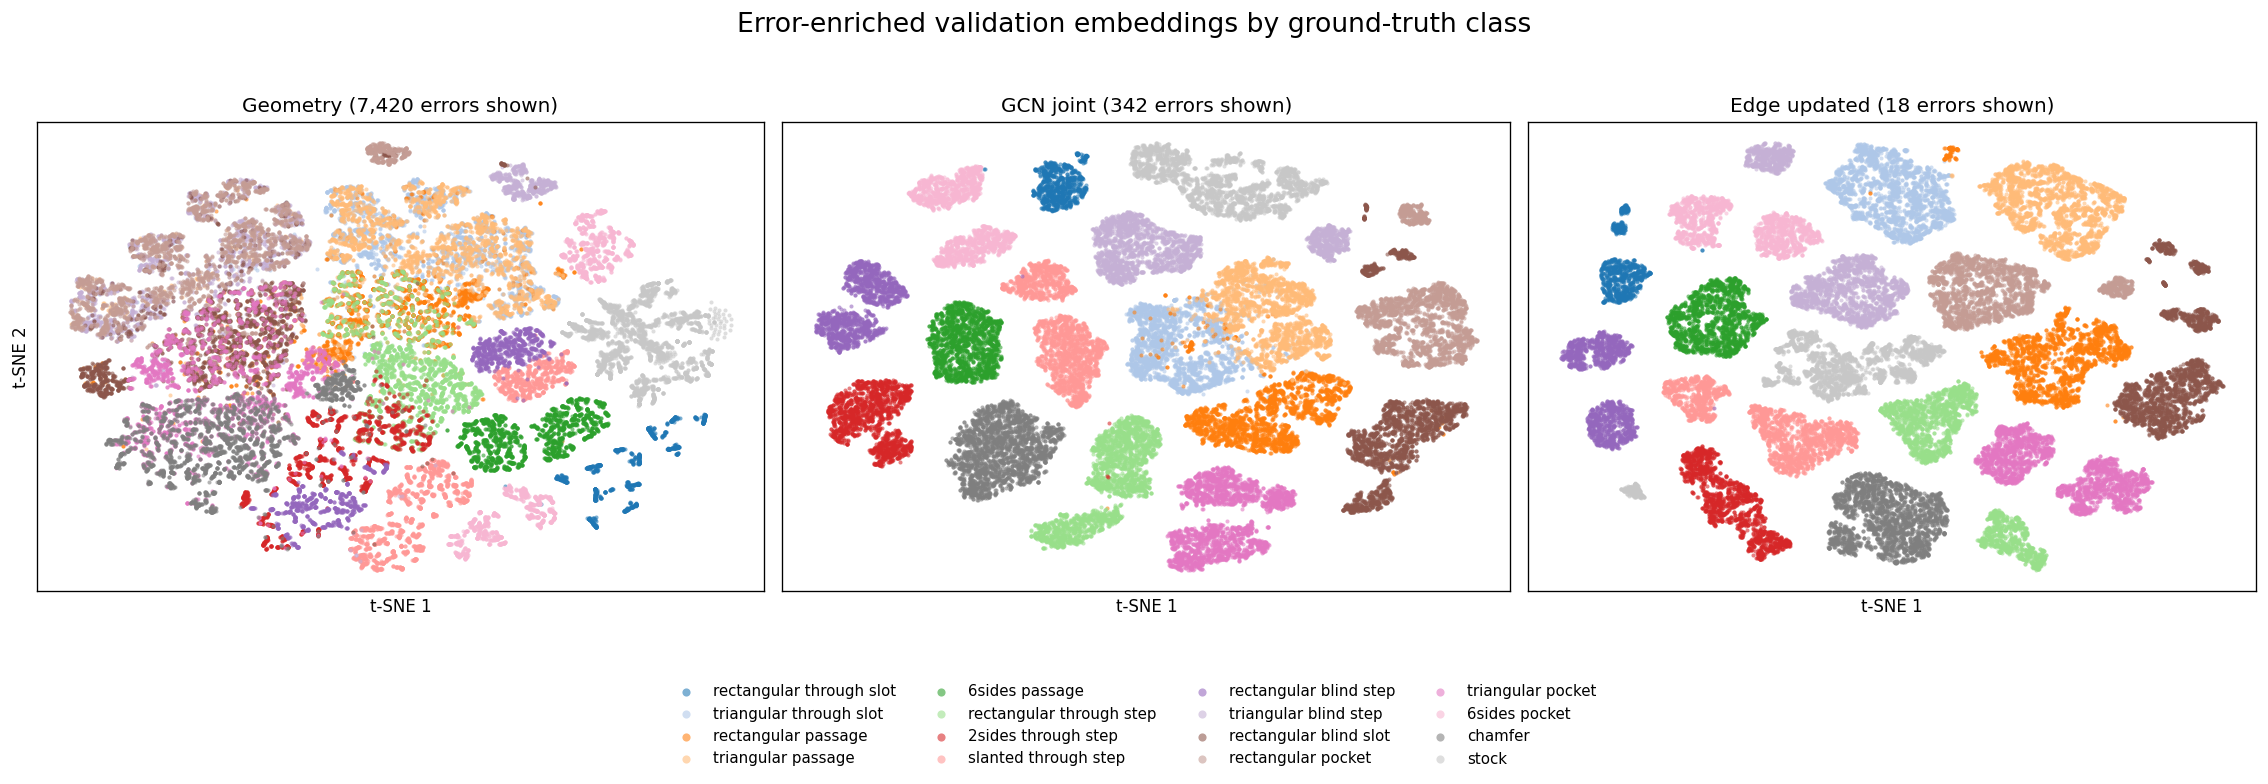

Saved: /Users/yongjun/Workspace/NUS/CS5284/project/results/embedding_analysis/embedding_tsne_ground_truth.png


In [10]:
tsne_cache_path = output_dir / "embedding_tsne_coordinates.csv"
tsne_coordinates = {}
reuse_tsne_cache = False
if tsne_cache_path.is_file():
    cached_tsne_table = pd.read_csv(tsne_cache_path)
    reuse_tsne_cache = set(cached_tsne_table["model"]) == set(tsne_models)
    if reuse_tsne_cache:
        for name in tsne_models:
            cached_rows = cached_tsne_table[cached_tsne_table["model"] == name]
            if cached_rows["source_face_row"].tolist() != selected_indices.tolist():
                reuse_tsne_cache = False
                break

if reuse_tsne_cache:
    tsne_table = cached_tsne_table
    for name in tsne_models:
        rows = tsne_table[tsne_table["model"] == name]
        tsne_coordinates[name] = rows[["tsne_x", "tsne_y"]].to_numpy()
    print("Reused aligned t-SNE coordinate cache.")
else:
    tsne_rows = []
    for name in tsne_models:
        values = selected_embeddings[name]
        pca_dim = min(50, values.shape[1], values.shape[0] - 1)
        reduced = PCA(n_components=pca_dim, random_state=0).fit_transform(values)
        coordinates = TSNE(
            n_components=2, perplexity=30, init="pca", learning_rate="auto",
            n_iter=1000, method="barnes_hut", angle=0.5,
            random_state=0, verbose=0,
        ).fit_transform(reduced)
        tsne_coordinates[name] = coordinates
        selected_model_correct = ~wrong_masks[name][selected_indices]
        for source_index, class_index, is_correct, is_union_error, (x_coord, y_coord) in zip(
            selected_indices.tolist(), selected_labels.tolist(),
            selected_model_correct.tolist(), any_wrong[selected_indices].tolist(), coordinates
        ):
            tsne_rows.append(dict(
                model=name, source_face_row=source_index,
                class_index=class_index, class_name=class_names[class_index],
                correct=bool(is_correct), union_error_sample=bool(is_union_error),
                tsne_x=float(x_coord), tsne_y=float(y_coord),
            ))
    tsne_table = pd.DataFrame(tsne_rows)
    tsne_table.to_csv(tsne_cache_path, index=False)

cmap = plt.get_cmap("tab20")
class_colors = {class_index: cmap(class_index) for class_index in range(num_classes)}
fig, axes = plt.subplots(1, 3, figsize=(19, 6.4))
for ax, name in zip(axes, tsne_models):
    coordinates = tsne_coordinates[name]
    for class_index in range(num_classes):
        mask = selected_labels.numpy() == class_index
        ax.scatter(
            coordinates[mask, 0], coordinates[mask, 1],
            s=6, alpha=0.58, linewidths=0, rasterized=True,
            color=class_colors[class_index],
            label=class_names[class_index].replace("_", " "),
        )
    model_errors_in_sample = int(wrong_masks[name][selected_indices].sum())
    ax.set_title(f"{name} ({model_errors_in_sample:,} errors shown)")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("t-SNE 1")
    if ax is axes[0]:
        ax.set_ylabel("t-SNE 2")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, -0.02), markerscale=2.0, fontsize=9)
fig.suptitle("Error-enriched validation embeddings by ground-truth class", fontsize=16)
fig.tight_layout(rect=(0, 0.17, 1, 0.95))
tsne_figure_path = output_dir / "embedding_tsne_ground_truth.png"
fig.savefig(tsne_figure_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", tsne_figure_path)


### t-SNE observations

The error-enriched view strengthens the visual progression across the ladder.

- **Geometry:** all 7,420 errors are present, and the large mixed central and lower regions make the ambiguity between several ground-truth classes explicit.
- **GCN joint:** all 342 errors remain in the sample, but most ground-truth classes now occupy much cleaner local neighbourhoods. The remaining colour mixing is concentrated in a few regions rather than spread throughout the embedding.
- **Edge updated:** all 18 errors are shown. Despite deliberately retaining every failure from the ladder, its classes remain the most compact and cleanly separated.

The shared sample contains all 7,533 faces misclassified by at least one of the three models plus 29,181 faces correctly classified by all three. The largest class-level union-error pool is 1,298, giving a target of 2,596 faces for classes with sufficient support; smaller classes contribute their full population. This enrichment makes failure regions visible while retaining substantial correct-class context.

Several labels still occupy multiple islands, which can reflect distinct neighbourhood contexts within the same face class. The plot remains qualitative: t-SNE can exaggerate local separation, and the deliberately biased sample is not an estimate of the validation distribution.


## t-SNE visualization of the three shallow topology models

Reuse the exact error-enriched face rows selected above and colour by the same ground-truth classes. Compare the **complete frozen shallow-model inputs before their classifiers**:

- **Laplacian:** 64D Geometry embedding + 8 Laplacian coordinates = 72 dimensions.
- **WL (T=3):** 64D Geometry embedding + the exact sparse one-hot representation of four WL colour rounds = 128,253 logical dimensions.
- **Graphlets (≤4):** 64D Geometry embedding + 15 standardized graphlet-orbit features = 79 dimensions.

Apply centred PCA to the dense Laplacian and graphlet concatenations. For WL, calculate the same centred truncated PCA scores through a sparse linear operator, avoiding a dense 36,714 × 128,253 allocation while preserving the complete logical concatenation. Then run t-SNE with the same settings used above.

The selected rows were deliberately enriched using errors from Geometry, GCN joint and Edge updated, rather than errors from these shallow models. This keeps the face set identical across both figures but means it is not a shallow-model error sample.


In [11]:
from scipy import sparse
from scipy.sparse.linalg import LinearOperator, svds

shallow_tsne_models = ["Laplacian", "WL (T=3)", "Graphlets (≤4)"]
shallow_runs = {
    "Laplacian": "laplacian_run_01",
    "WL (T=3)": "wl3_frozen_run_01",
    "Graphlets (≤4)": "graphlet4_frozen_run_01",
}
shallow_cached_predictions = {
    name: torch.load(
        project_dir / "results" / run / "epoch_020/validation_predictions.pt",
        map_location="cpu", weights_only=True,
    )
    for name, run in shallow_runs.items()
}
for name, result in shallow_cached_predictions.items():
    if not torch.equal(result["labels"].cpu(), labels_all):
        raise ValueError(f"Validation label order mismatch: {name}")

selected_laplacian = []
selected_wl_tokens = []
selected_graphlets = []
global_start = 0
with torch.no_grad():
    for sample in tqdm(ValidationGraphDataset(validation_ids),
                       desc="Extract shallow full-concat inputs"):
        n = len(sample["labels"])
        global_stop = global_start + n
        local_mask = selected_mask[global_start:global_stop]
        if local_mask.any():
            graph = sample["graph"]
            selected_laplacian.append(
                laplacian_positional_encoding(graph, laplacian_dim)[local_mask]
            )
            selected_wl_tokens.append(encode_wl_colors(
                wl_node_colors(graph, wl_vocabulary["iterations"]),
                wl_vocabulary, wl_maps,
            )[local_mask])
            graphlet_raw = graphlet_degree_vectors(
                graph, max_nodes=graphlet_max_nodes, normalize=True
            )
            selected_graphlets.append(
                ((graphlet_raw - graphlet_mean) / graphlet_scale)[local_mask]
            )
        global_start = global_stop

if global_start != len(labels_all):
    raise ValueError("Shallow extraction did not cover all validation faces.")
selected_laplacian = torch.cat(selected_laplacian).numpy()
selected_wl_tokens = torch.cat(selected_wl_tokens).numpy()
selected_graphlets = torch.cat(selected_graphlets).numpy()
selected_geometry = selected_embeddings["Geometry"]
n_selected = len(selected_indices)
if not all(len(values) == n_selected for values in
           (selected_geometry, selected_laplacian, selected_wl_tokens, selected_graphlets)):
    raise ValueError("Shallow concatenation row alignment failed.")

laplacian_full = np.concatenate([selected_geometry, selected_laplacian], axis=1)
graphlet_full = np.concatenate([selected_geometry, selected_graphlets], axis=1)

rounds = selected_wl_tokens.shape[1]
wl_rows = np.repeat(np.arange(n_selected), rounds)
wl_columns = selected_wl_tokens.reshape(-1)
wl_unknown = np.tile(np.asarray(wl_vocabulary["unknown_indices"]), n_selected)
wl_known = wl_columns != wl_unknown
wl_one_hot = sparse.csr_matrix(
    (np.ones(wl_known.sum(), dtype=np.float32),
     (wl_rows[wl_known], wl_columns[wl_known])),
    shape=(n_selected, wl_vocabulary["size"]),
)
wl_full = sparse.hstack(
    [sparse.csr_matrix(selected_geometry), wl_one_hot], format="csr"
)

full_input_shapes = pd.DataFrame({
    "rows": [laplacian_full.shape[0], wl_full.shape[0], graphlet_full.shape[0]],
    "full_concat_dimension": [laplacian_full.shape[1], wl_full.shape[1], graphlet_full.shape[1]],
}, index=shallow_tsne_models)
display(full_input_shapes)


Extract shallow full-concat inputs:   0%|          | 0/3090 [00:00<?, ?it/s]

,rows,full_concat_dimension
Laplacian,36714,72
WL (T=3),36714,128253
Graphlets (≤4),36714,79


In [12]:
def centered_sparse_pca_scores(matrix, n_components=50, random_state=0):
    matrix = sparse.csr_matrix(matrix, dtype=np.float64)
    n_rows, n_columns = matrix.shape
    mean = np.asarray(matrix.mean(axis=0)).ravel()
    ones = np.ones(n_rows, dtype=np.float64)

    operator = LinearOperator(
        matrix.shape, dtype=np.float64,
        matvec=lambda vector: np.asarray(matrix @ vector).ravel() - ones * mean.dot(vector),
        rmatvec=lambda vector: np.asarray(matrix.T @ vector).ravel() - mean * vector.sum(),
        matmat=lambda values: np.asarray(matrix @ values) - np.outer(ones, mean @ values),
        rmatmat=lambda values: np.asarray(matrix.T @ values) - mean[:, None] * values.sum(axis=0),
    )
    left, singular_values, _ = svds(
        operator, k=n_components, which="LM", solver="arpack",
        random_state=random_state,
    )
    order = np.argsort(singular_values)[::-1]
    singular_values = singular_values[order]
    scores = left[:, order] * singular_values
    centered_sum_squares = float(matrix.multiply(matrix).sum() - n_rows * mean.dot(mean))
    explained_ratio = float(np.square(singular_values).sum() / centered_sum_squares)
    return scores.astype(np.float32), explained_ratio

shallow_pca = {}
pca_rows = []
for name, values in {
    "Laplacian": laplacian_full,
    "Graphlets (≤4)": graphlet_full,
}.items():
    reducer = PCA(n_components=50, random_state=0)
    shallow_pca[name] = reducer.fit_transform(values)
    pca_rows.append(dict(model=name, input_dimension=values.shape[1],
                         components=50,
                         explained_variance_percent=100 * reducer.explained_variance_ratio_.sum()))

shallow_pca["WL (T=3)"], wl_explained_ratio = centered_sparse_pca_scores(
    wl_full, n_components=50, random_state=0
)
pca_rows.append(dict(model="WL (T=3)", input_dimension=wl_full.shape[1],
                     components=50,
                     explained_variance_percent=100 * wl_explained_ratio))
pca_summary = pd.DataFrame(pca_rows).set_index("model").reindex(shallow_tsne_models)
display(pca_summary.style.format({"input_dimension": "{:,.0f}",
                                  "components": "{:,.0f}",
                                  "explained_variance_percent": "{:.2f}%"}))


,input_dimension,components,explained_variance_percent
model,,,
Laplacian,72,50,98.35%
WL (T=3),"128,253",50,96.04%
Graphlets (≤4),79,50,98.28%


Reused shallow full-concatenation t-SNE coordinate cache.


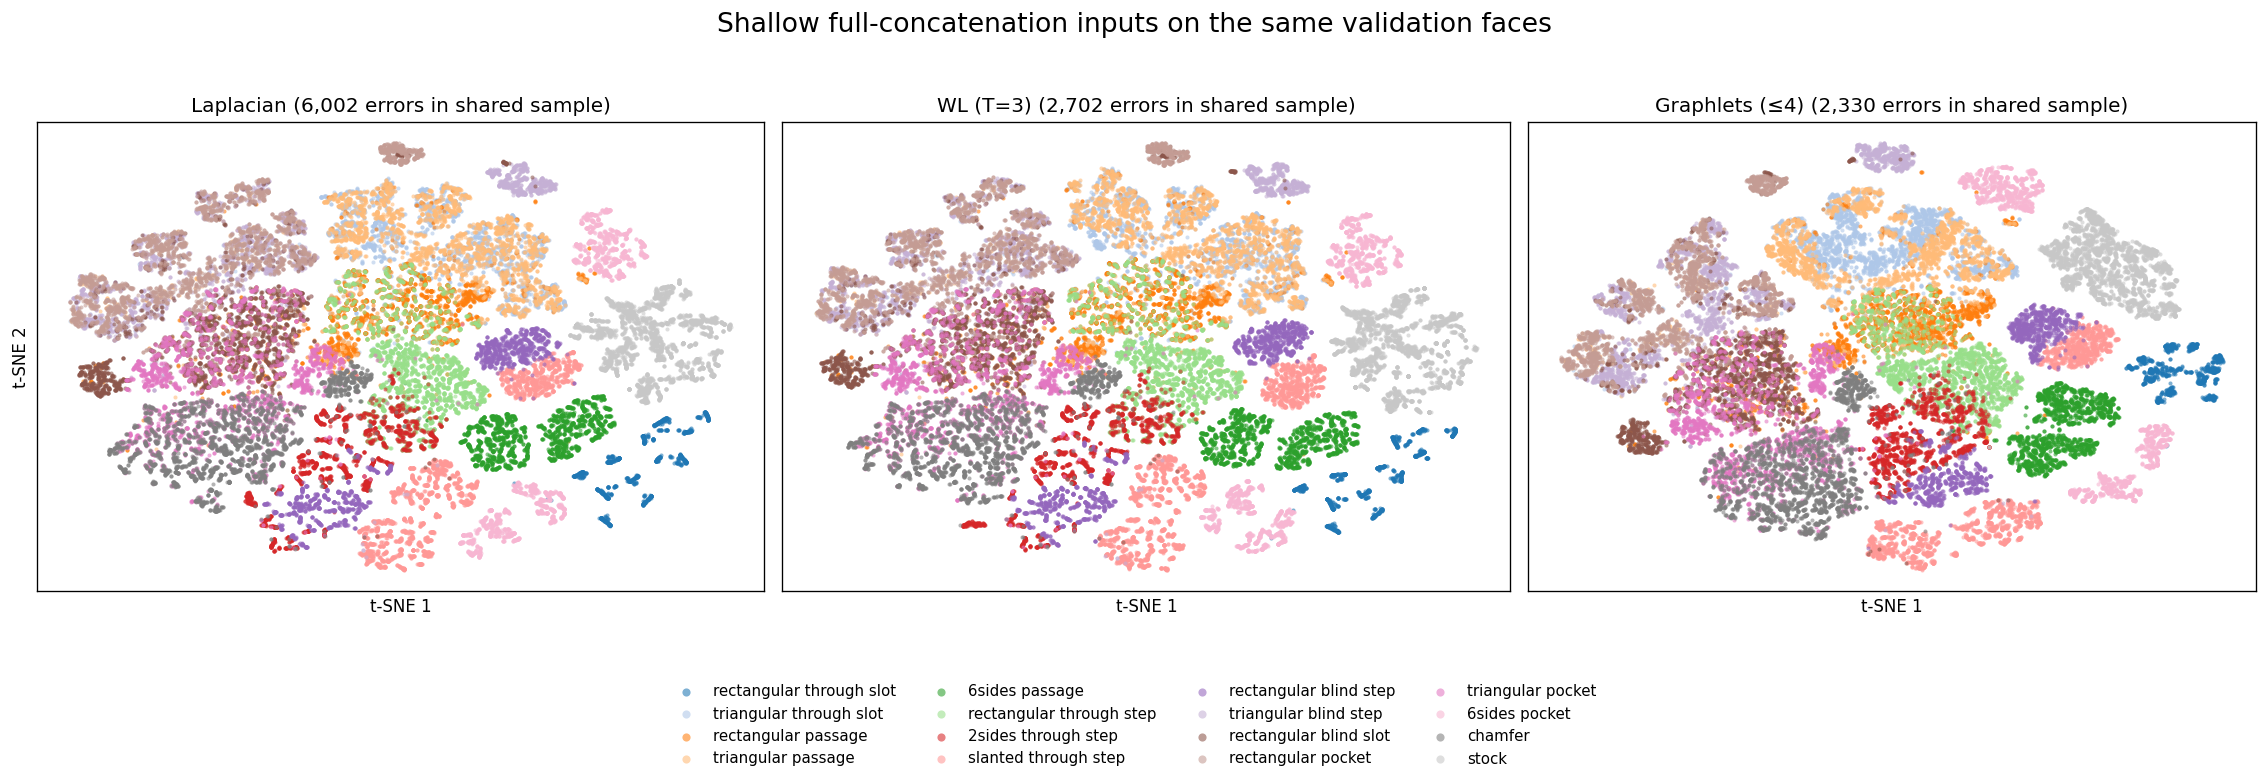

Saved: /Users/yongjun/Workspace/NUS/CS5284/project/results/embedding_analysis/shallow_full_concat_tsne_ground_truth.png


In [13]:
shallow_concat_cache_path = output_dir / "shallow_full_concat_tsne_coordinates.csv"
shallow_tsne_coordinates = {}
reuse_shallow_concat_cache = False
if shallow_concat_cache_path.is_file():
    cached_shallow_concat = pd.read_csv(shallow_concat_cache_path)
    reuse_shallow_concat_cache = set(cached_shallow_concat["model"]) == set(shallow_tsne_models)
    if reuse_shallow_concat_cache:
        for name in shallow_tsne_models:
            cached_rows = cached_shallow_concat[cached_shallow_concat["model"] == name]
            if cached_rows["source_face_row"].tolist() != selected_indices.tolist():
                reuse_shallow_concat_cache = False
                break

if reuse_shallow_concat_cache:
    shallow_tsne_table = cached_shallow_concat
    for name in shallow_tsne_models:
        rows = shallow_tsne_table[shallow_tsne_table["model"] == name]
        shallow_tsne_coordinates[name] = rows[["tsne_x", "tsne_y"]].to_numpy()
    print("Reused shallow full-concatenation t-SNE coordinate cache.")
else:
    shallow_tsne_rows = []
    for name in shallow_tsne_models:
        coordinates = TSNE(
            n_components=2, perplexity=30, init="pca", learning_rate="auto",
            n_iter=1000, method="barnes_hut", angle=0.5,
            random_state=0, verbose=0,
        ).fit_transform(shallow_pca[name])
        shallow_tsne_coordinates[name] = coordinates
        model_predictions = shallow_cached_predictions[name]["predictions"].cpu()
        for source_index, class_index, (x_coord, y_coord) in zip(
            selected_indices.tolist(), selected_labels.tolist(), coordinates
        ):
            shallow_tsne_rows.append(dict(
                model=name, source_face_row=source_index,
                class_index=class_index, class_name=class_names[class_index],
                correct=bool(model_predictions[source_index] == labels_all[source_index]),
                union_error_sample=bool(any_wrong[source_index]),
                tsne_x=float(x_coord), tsne_y=float(y_coord),
            ))
    shallow_tsne_table = pd.DataFrame(shallow_tsne_rows)
    shallow_tsne_table.to_csv(shallow_concat_cache_path, index=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 6.4))
for ax, name in zip(axes, shallow_tsne_models):
    coordinates = shallow_tsne_coordinates[name]
    for class_index in range(num_classes):
        mask = selected_labels.numpy() == class_index
        ax.scatter(
            coordinates[mask, 0], coordinates[mask, 1],
            s=6, alpha=0.58, linewidths=0, rasterized=True,
            color=class_colors[class_index],
            label=class_names[class_index].replace("_", " "),
        )
    errors_in_sample = int((
        shallow_cached_predictions[name]["predictions"].cpu()[selected_indices]
        != selected_labels
    ).sum())
    ax.set_title(f"{name} ({errors_in_sample:,} errors in shared sample)")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("t-SNE 1")
    if ax is axes[0]:
        ax.set_ylabel("t-SNE 2")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, -0.02), markerscale=2.0, fontsize=9)
fig.suptitle("Shallow full-concatenation inputs on the same validation faces", fontsize=16)
fig.tight_layout(rect=(0, 0.17, 1, 0.95))
shallow_tsne_figure_path = output_dir / "shallow_full_concat_tsne_ground_truth.png"
fig.savefig(shallow_tsne_figure_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", shallow_tsne_figure_path)


### Shallow-model t-SNE observations

The Laplacian and WL full-concatenation layouts remain strikingly close to the Geometry layout, while Graphlets produces the clearest reorganization of the three shallow inputs. This broadly follows their predictive ordering on the shared sample: Laplacian has 6,002 errors, WL 2,702 and Graphlets 2,330.

The similarity to Geometry is also a warning about the visualization method. The first 50 components explain 98.35% of Laplacian variance, 96.04% of WL variance and 98.28% of Graphlet variance, but much of that variance comes from the shared 64-dimensional Geometry embedding. A topology feature can have comparatively low variance yet still be strongly amplified by the trained classifier and improve decisions. Consequently, PCA followed by t-SNE of the raw concatenation can visually understate the contribution of shallow topology—especially sparse WL categories.

Graphlets visibly changes more neighbourhood structure, consistent with its motif features reacting strongly to local topology and its slightly better accuracy than WL. Even so, the substantial class mixing shows why these shallow additions do not achieve the separation seen after learned GCN and edge message passing. The sample remains biased toward errors from the later model ladder, so error counts in the titles describe this shared set rather than the full validation population.


## t-SNE after the first shallow classifier layer

Repeat the shallow comparison using the learned 128-dimensional hidden activation after each model's first classifier operation and ReLU:

\[
h^{(1)}=\operatorname{ReLU}(W_{\mathrm{geo}}h_{\mathrm{geo}} + W_{\mathrm{topo}}h_{\mathrm{topo}} + b).
\]

For WL, the colour embedding lookup and sum exactly implements the categorical topology block of this linear layer without materializing its 128,189-dimensional one-hot vector. Unlike the earlier topology-only energy calculation, this representation includes the complete geometry contribution, topology contribution and learned bias. Use the same shared face rows, reduce each 128D activation to 50 PCA components, and apply the same t-SNE configuration.


In [14]:
import torch.nn.functional as F

laplacian_state = laplacian_checkpoint["model_state_dict"]
graphlet_state = graphlet_checkpoint["model_state_dict"]

with torch.no_grad():
    laplacian_hidden = torch.relu(F.linear(
        torch.from_numpy(laplacian_full).float(),
        laplacian_state["linear1.weight"],
        laplacian_state["linear1.bias"],
    )).numpy()

    graphlet_hidden = torch.relu(F.linear(
        torch.from_numpy(graphlet_full).float(),
        graphlet_state["linear1.weight"],
        graphlet_state["linear1.bias"],
    )).numpy()

    wl_token_tensor = torch.from_numpy(selected_wl_tokens).long()
    wl_color_values = wl_model.color_projection(wl_token_tensor)
    wl_known_tensor = (wl_token_tensor != wl_model.unknown_indices).unsqueeze(-1)
    wl_hidden = torch.relu(
        wl_model.geometry_projection(torch.from_numpy(selected_geometry).float())
        + (wl_color_values * wl_known_tensor).sum(dim=1)
    ).numpy()

shallow_first_layer = {
    "Laplacian": laplacian_hidden,
    "WL (T=3)": wl_hidden,
    "Graphlets (≤4)": graphlet_hidden,
}
first_layer_shapes = {name: values.shape for name, values in shallow_first_layer.items()}
if set(first_layer_shapes.values()) != {(len(selected_indices), 128)}:
    raise ValueError(f"Unexpected first-layer shapes: {first_layer_shapes}")
print(first_layer_shapes)


{'Laplacian': (36714, 128), 'WL (T=3)': (36714, 128), 'Graphlets (≤4)': (36714, 128)}


,hidden_dimension,components,explained_variance_percent
model,,,
Laplacian,128,50,99.16%
WL (T=3),128,50,99.73%
Graphlets (≤4),128,50,98.86%


Reused shallow first-layer t-SNE coordinate cache.


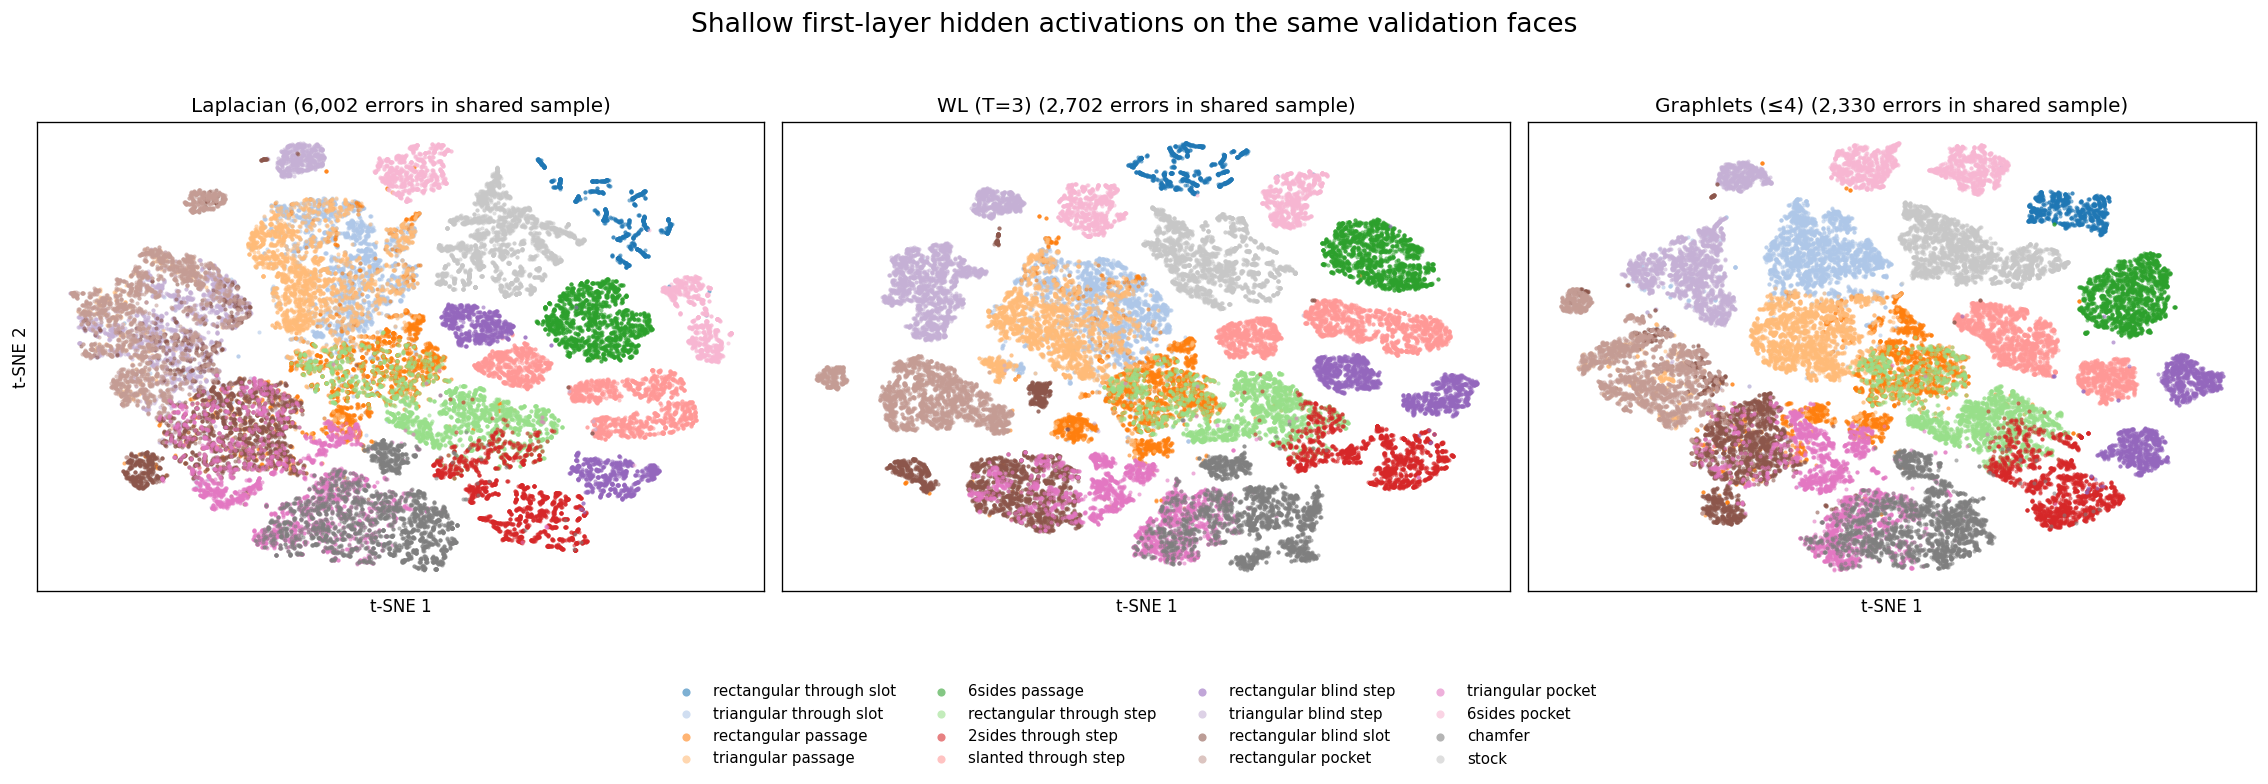

Saved: /Users/yongjun/Workspace/NUS/CS5284/project/results/embedding_analysis/shallow_first_layer_tsne_ground_truth.png


In [15]:
first_layer_pca = {}
first_layer_pca_rows = []
for name in shallow_tsne_models:
    reducer = PCA(n_components=50, random_state=0)
    first_layer_pca[name] = reducer.fit_transform(shallow_first_layer[name])
    first_layer_pca_rows.append(dict(
        model=name, hidden_dimension=shallow_first_layer[name].shape[1],
        components=50,
        explained_variance_percent=100 * reducer.explained_variance_ratio_.sum(),
    ))
first_layer_pca_summary = (
    pd.DataFrame(first_layer_pca_rows).set_index("model").reindex(shallow_tsne_models)
)
display(first_layer_pca_summary.style.format({
    "hidden_dimension": "{:,.0f}", "components": "{:,.0f}",
    "explained_variance_percent": "{:.2f}%",
}))

first_layer_cache_path = output_dir / "shallow_first_layer_tsne_coordinates.csv"
first_layer_tsne_coordinates = {}
reuse_first_layer_cache = False
if first_layer_cache_path.is_file():
    cached_first_layer = pd.read_csv(first_layer_cache_path)
    reuse_first_layer_cache = set(cached_first_layer["model"]) == set(shallow_tsne_models)
    if reuse_first_layer_cache:
        for name in shallow_tsne_models:
            cached_rows = cached_first_layer[cached_first_layer["model"] == name]
            if cached_rows["source_face_row"].tolist() != selected_indices.tolist():
                reuse_first_layer_cache = False
                break

if reuse_first_layer_cache:
    first_layer_tsne_table = cached_first_layer
    for name in shallow_tsne_models:
        rows = first_layer_tsne_table[first_layer_tsne_table["model"] == name]
        first_layer_tsne_coordinates[name] = rows[["tsne_x", "tsne_y"]].to_numpy()
    print("Reused shallow first-layer t-SNE coordinate cache.")
else:
    first_layer_tsne_rows = []
    for name in shallow_tsne_models:
        coordinates = TSNE(
            n_components=2, perplexity=30, init="pca", learning_rate="auto",
            n_iter=1000, method="barnes_hut", angle=0.5,
            random_state=0, verbose=0,
        ).fit_transform(first_layer_pca[name])
        first_layer_tsne_coordinates[name] = coordinates
        model_predictions = shallow_cached_predictions[name]["predictions"].cpu()
        for source_index, class_index, (x_coord, y_coord) in zip(
            selected_indices.tolist(), selected_labels.tolist(), coordinates
        ):
            first_layer_tsne_rows.append(dict(
                model=name, source_face_row=source_index,
                class_index=class_index, class_name=class_names[class_index],
                correct=bool(model_predictions[source_index] == labels_all[source_index]),
                union_error_sample=bool(any_wrong[source_index]),
                tsne_x=float(x_coord), tsne_y=float(y_coord),
            ))
    first_layer_tsne_table = pd.DataFrame(first_layer_tsne_rows)
    first_layer_tsne_table.to_csv(first_layer_cache_path, index=False)

fig, axes = plt.subplots(1, 3, figsize=(19, 6.4))
for ax, name in zip(axes, shallow_tsne_models):
    coordinates = first_layer_tsne_coordinates[name]
    for class_index in range(num_classes):
        mask = selected_labels.numpy() == class_index
        ax.scatter(
            coordinates[mask, 0], coordinates[mask, 1],
            s=6, alpha=0.58, linewidths=0, rasterized=True,
            color=class_colors[class_index],
            label=class_names[class_index].replace("_", " "),
        )
    errors_in_sample = int((
        shallow_cached_predictions[name]["predictions"].cpu()[selected_indices]
        != selected_labels
    ).sum())
    ax.set_title(f"{name} ({errors_in_sample:,} errors in shared sample)")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("t-SNE 1")
    if ax is axes[0]:
        ax.set_ylabel("t-SNE 2")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, -0.02), markerscale=2.0, fontsize=9)
fig.suptitle("Shallow first-layer hidden activations on the same validation faces",
             fontsize=16)
fig.tight_layout(rect=(0, 0.17, 1, 0.95))
first_layer_tsne_figure_path = output_dir / "shallow_first_layer_tsne_ground_truth.png"
fig.savefig(first_layer_tsne_figure_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", first_layer_tsne_figure_path)


### First-layer t-SNE observations

The trained first layer produces a much more informative view than PCA on the raw concatenations. All three hidden spaces show stronger class organization, demonstrating that the classifier does not treat topology as a passive appended feature: its learned weights rescale and combine topology with geometry before classification.

- **Laplacian:** several classes become more coherent than in the raw-input plot, but large mixed regions remain. Its 6,002 errors in the shared sample are consistent with the weakest separation of the three.
- **WL (T=3):** the change from the raw-concatenation plot is substantial. Sparse WL categories that contributed little to the leading raw-input principal components become visible after the learned colour and geometry projections. Some major class pairs remain mixed, matching its 2,702 shared-sample errors.
- **Graphlets (≤4):** generally provides the cleanest shallow hidden representation, although it still contains important overlap. This is consistent with its slightly better predictive result and 2,330 errors in the shared sample.

The first 50 components retain 99.16% of Laplacian, 99.73% of WL and 98.86% of Graphlet hidden-layer variance, so little variance is discarded before t-SNE. The result explains why the first-layer representation is preferable for visualizing what each trained shallow classifier actually uses, while the raw concatenation remains useful for showing that ordinary PCA can hide sparse or low-variance topology signals. None of the shallow spaces reaches the clean separation visible after GCN and edge message passing.
